In [22]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import pearsonr, spearmanr
import warnings
warnings.filterwarnings('ignore')

df = pd.read_csv('data/student_mental_health_dataset.csv')
df.head()

,student_id,sleep_hours,study_hours,social_media_hours,exercise_minutes,class_attendance_percent,assignment_deadlines_missed,stress_level,focus_level,mental_health_score
0,1,6.2,5.4,3.9,36,67,2,4,10,52
1,2,9.7,6.4,1.0,78,62,0,8,8,96
2,3,8.4,2.0,5.2,75,79,4,2,7,99
3,4,7.6,5.0,3.7,60,88,1,7,8,96
4,5,4.9,4.6,0.9,78,84,0,3,1,34


In [23]:
df.info()
df.describe()

numeric_cols = ['social_media_hours', 'study_hours', 'sleep_hours',
                'stress_level', 'focus_level', 'mental_health_score']

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3000 entries, 0 to 2999
Data columns (total 10 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   student_id                   3000 non-null   int64  
 1   sleep_hours                  3000 non-null   float64
 2   study_hours                  3000 non-null   float64
 3   social_media_hours           3000 non-null   float64
 4   exercise_minutes             3000 non-null   int64  
 5   class_attendance_percent     3000 non-null   int64  
 6   assignment_deadlines_missed  3000 non-null   int64  
 7   stress_level                 3000 non-null   int64  
 8   focus_level                  3000 non-null   int64  
 9   mental_health_score          3000 non-null   int64  
dtypes: float64(3), int64(7)
memory usage: 234.5 KB


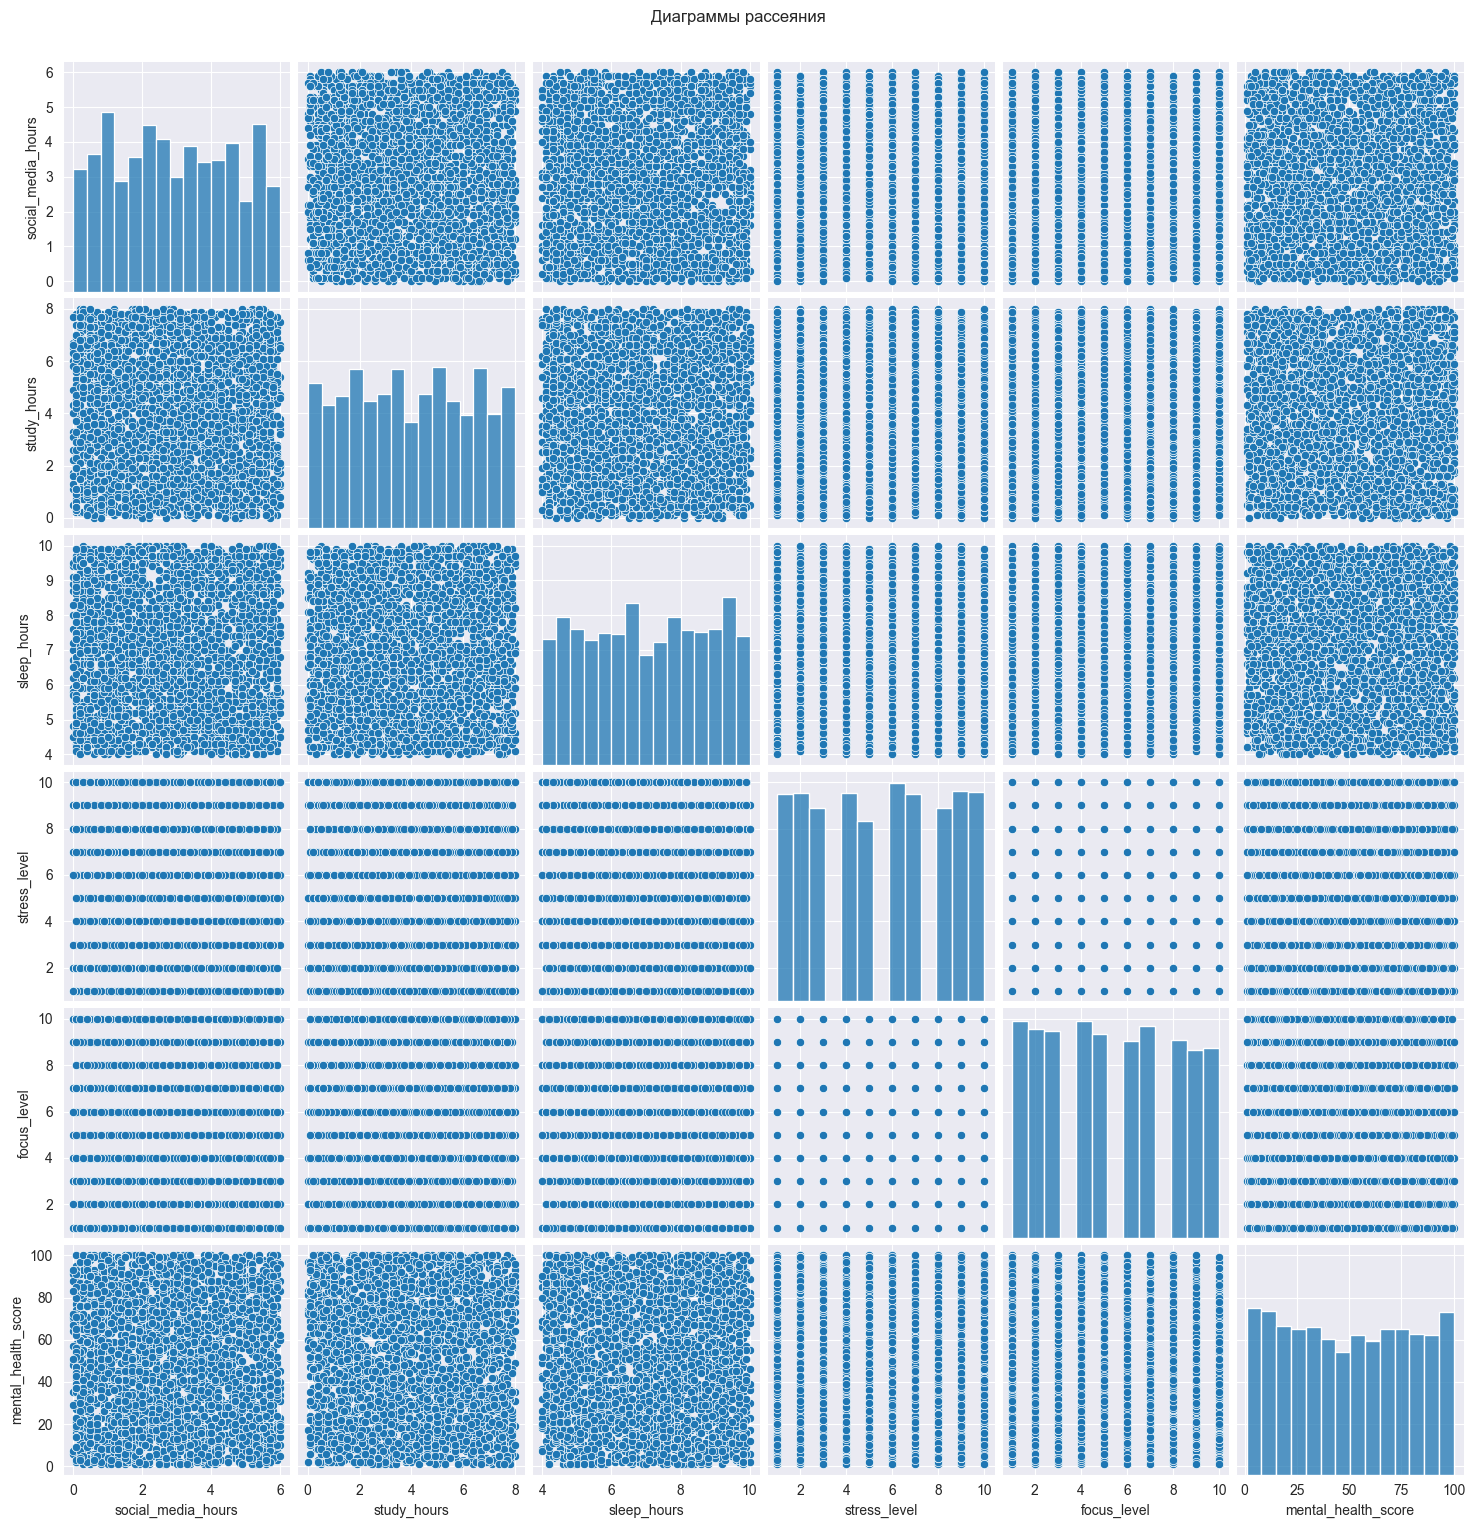

In [24]:
sns.pairplot(df[numeric_cols])
plt.suptitle('Диаграммы рассеяния', y=1.02)
plt.show()

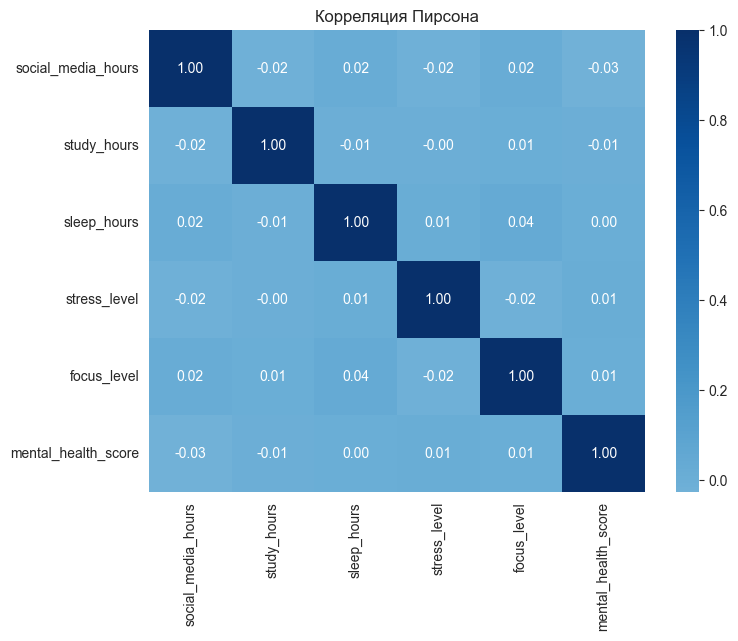

In [25]:
corr_pearson = df[numeric_cols].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr_pearson, annot=True, cmap='Blues', fmt='.2f', center=0)
plt.title('Корреляция Пирсона')
plt.show()

In [26]:
alpha = 0.05
results_pearson = []

target = 'social_media_hours'
other_cols = ['study_hours', 'sleep_hours', 'stress_level', 'focus_level', 'mental_health_score']

for col in other_cols:
    mask = df[target].notna() & df[col].notna()
    r, p = pearsonr(df.loc[mask, target], df.loc[mask, col])
    results_pearson.append({
        'Переменная': col,
        'r': r,
        'p': p,
        'Значима (p<0.05)': p < alpha
    })

pd.DataFrame(results_pearson)

,Переменная,r,p,Значима (p<0.05)
0,study_hours,-0.018956,0.299298,False
1,sleep_hours,0.024185,0.185402,False
2,stress_level,-0.021610,0.236695,False
3,focus_level,0.020369,0.264717,False
4,mental_health_score,-0.026812,0.142049,False


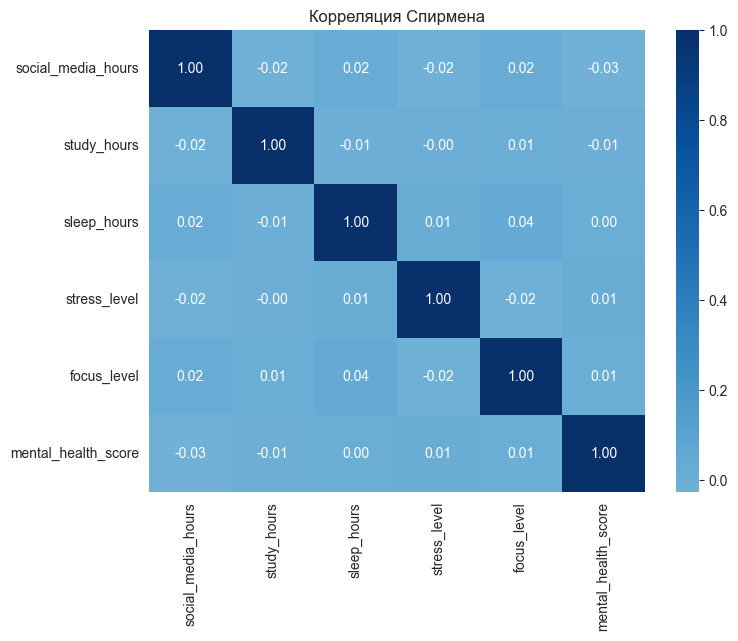

In [27]:
corr_spearman = df[numeric_cols].corr(method='spearman')

plt.figure(figsize=(8, 6))
sns.heatmap(corr_spearman, annot=True, cmap='Blues', fmt='.2f', center=0)
plt.title('Корреляция Спирмена')
plt.show()

In [28]:
results_spearman = []

for col in other_cols:
    mask = df[target].notna() & df[col].notna()
    r, p = spearmanr(df.loc[mask, target], df.loc[mask, col])
    results_spearman.append({
        'Переменная': col,
        'r': r,
        'p': p,
        'Значима (p<0.05)': p < alpha
    })

pd.DataFrame(results_spearman)

,Переменная,r,p,Значима (p<0.05)
0,study_hours,-0.018785,0.303683,False
1,sleep_hours,0.023679,0.194777,False
2,stress_level,-0.020944,0.251468,False
3,focus_level,0.020791,0.254951,False
4,mental_health_score,-0.026958,0.139891,False


# *

In [33]:
def partial_corr(x, y, z):
    r_xy = pearsonr(x, y)[0]
    r_xz = pearsonr(x, z)[0]
    r_yz = pearsonr(y, z)[0]
    return (r_xy - r_xz * r_yz) / np.sqrt((1 - r_xz**2) * (1 - r_yz**2))

covariates = ['study_hours', 'sleep_hours', 'stress_level', 'focus_level']
partial_results = []

mask = df[['social_media_hours', 'mental_health_score'] + covariates].notna().all(axis=1)
df_clean = df.loc[mask]

x = df_clean['social_media_hours']
y = df_clean['mental_health_score']

for cov in covariates:
    z = df_clean[cov]
    r_partial = partial_corr(x, y, z)
    partial_results.append({
        'Контролируемая переменная': cov,
        'r (частная)': r_partial
    })

pd.DataFrame(partial_results)

,Контролируемая переменная,r (частная)
0,study_hours,-0.026939
1,sleep_hours,-0.026918
2,stress_level,-0.026586
3,focus_level,-0.026975


In [34]:
def interpret_correlation(r, p, alpha=0.05):
    if p >= alpha:
        return 'не значима'
    r_abs = abs(r)
    if r_abs < 0.2:
        return 'нет корреляции'
    elif r_abs < 0.5:
        return 'слабая'
    elif r_abs < 0.7:
        return 'средняя'
    else:
        return 'сильная'

print("Связь соцсетей с другими показателями (Спирмен):")
for res in results_spearman:
    strength = interpret_correlation(res['r'], res['p'])
    direction = 'прямая' if res['r'] > 0 else 'обратная'
    print(f"  {res['Переменная']}: r={res['r']:.3f}, {strength} {direction} связь")

Связь соцсетей с другими показателями (Спирмен):
  study_hours: r=-0.019, не значима обратная связь
  sleep_hours: r=0.024, не значима прямая связь
  stress_level: r=-0.021, не значима обратная связь
  focus_level: r=0.021, не значима прямая связь
  mental_health_score: r=-0.027, не значима обратная связь


In [36]:
sig_results = [r for r in results_spearman if r['Значима (p<0.05)']]
if sig_results:
    print("Статистически значимые корреляции с временем в соцсетях:")
    for res in sig_results:
        print(f"  - {res['Переменная']}: r = {res['r']:.3f}")
else:
    print("Статистически значимых корреляций не обнаружено.")

print("\nЧастные корреляции (соцсети — mental_health_score):")
for pr in partial_results:
    print(f"  - при контроле {pr['Контролируемая переменная']}: r = {pr['r (частная)']:.3f}")

Статистически значимых корреляций не обнаружено.

Частные корреляции (соцсети — mental_health_score):
  - при контроле study_hours: r = -0.027
  - при контроле sleep_hours: r = -0.027
  - при контроле stress_level: r = -0.027
  - при контроле focus_level: r = -0.027
